In [ ]:
%pip install yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
sectors = {
    "AAPL": "Tech", "NVDA": "Tech",
    "XOM": "Energy", "CVX": "Energy",
    "JPM": "Banks", "BAC": "Banks",
    "JNJ": "Healthcare", "PFE": "Healthcare"
}

tickers = list(sectors.keys())

In [ ]:
prices = yf.download(tickers, start="2022-01-01", end="2025-01-01")["Close"]
prices = prices[tickers]

print(prices.shape)
print(prices.head())
print(prices.isna().sum())

/tmp/ipykernel_829/2216723508.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start="2022-01-01", end="2025-01-01")["Close"]
[*********************100%***********************]  8 of 8 completed


(753, 8)
Ticker            AAPL       NVDA        XOM         CVX         JPM  \
Date                                                                   
2022-01-03  177.786407  29.992584  54.041134   98.725586  142.832352   
2022-01-04  175.529984  29.165129  56.073856  100.521942  148.247070   
2022-01-05  170.860931  27.486315  56.771252  101.175919  145.536804   
2022-01-06  168.008698  28.057865  58.106556  102.036858  147.083008   
2022-01-07  168.174744  27.130836  58.582829  103.502083  148.540329   

Ticker            BAC         JNJ        PFE  
Date                                          
2022-01-03  41.055870  150.161575  43.230511  
2022-01-04  42.665039  149.758957  41.612713  
2022-01-05  41.944912  150.756866  42.452137  
2022-01-06  42.789509  150.240387  41.849281  
2022-01-07  43.722988  152.271210  42.520821  
Ticker
AAPL    0
NVDA    0
XOM     0
CVX     0
JPM     0
BAC     0
JNJ     0
PFE     0
dtype: int64


In [ ]:
returns = prices.pct_change().dropna()
print(returns.head())

Ticker          AAPL      NVDA       XOM       CVX       JPM       BAC  \
Date                                                                     
2022-01-04 -0.012692 -0.027589  0.037614  0.018195  0.037910  0.039195   
2022-01-05 -0.026600 -0.057562  0.012437  0.006506 -0.018282 -0.016879   
2022-01-06 -0.016693  0.020794  0.023521  0.008509  0.010624  0.020136   
2022-01-07  0.000988 -0.033040  0.008197  0.014360  0.009908  0.021816   
2022-01-10  0.000116  0.005615 -0.005952  0.000640  0.000957 -0.005083   

Ticker           JNJ       PFE  
Date                            
2022-01-04 -0.002681 -0.037423  
2022-01-05  0.006663  0.020172  
2022-01-06 -0.003426 -0.014201  
2022-01-07  0.013517  0.016047  
2022-01-10 -0.004944  0.009332  


In [ ]:
mu = returns.mean() * 252
sigma = returns.cov() * 252

print("Expected yearly returns:")
print(mu.round(3))
print("\nCovariance matrix:")
print(sigma.round(3))

Expected yearly returns:
Ticker
AAPL    0.149
NVDA    0.652
XOM     0.249
CVX     0.137
JPM     0.191
BAC     0.048
JNJ    -0.015
PFE    -0.179
dtype: float64

Covariance matrix:
Ticker   AAPL   NVDA    XOM    CVX    JPM    BAC    JNJ    PFE
Ticker                                                        
AAPL    0.073  0.083  0.013  0.014  0.024  0.027  0.008  0.014
NVDA    0.083  0.305  0.009  0.018  0.045  0.046 -0.005  0.008
XOM     0.013  0.009  0.074  0.059  0.020  0.024  0.005  0.011
CVX     0.014  0.018  0.059  0.066  0.022  0.027  0.006  0.011
JPM     0.024  0.045  0.020  0.022  0.062  0.055  0.011  0.015
BAC     0.027  0.046  0.024  0.027  0.055  0.076  0.011  0.016
JNJ     0.008 -0.005  0.005  0.006  0.011  0.011  0.027  0.019
PFE     0.014  0.008  0.011  0.011  0.015  0.016  0.019  0.060


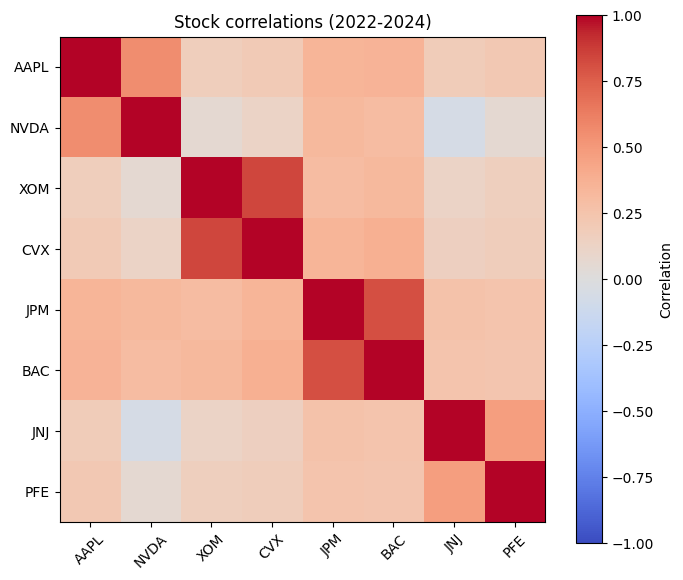

In [ ]:
corr = returns.corr()

plt.figure(figsize=(7,6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(tickers)), tickers, rotation=45)
plt.yticks(range(len(tickers)),tickers)
plt.title("Stock correlations (2022-2024)")
plt.tight_layout()
plt.show()

In [ ]:
prices.to_csv("prices.csv")
mu.to_csv("mu.csv")
sigma.to_csv("sigma.csv")

In [ ]:
mu_arr = mu.values
sigma_arr = sigma.values
n = len(tickers)


In [ ]:
#from google.colab import files

#files.download("prices.csv")
#files.download("mu.csv")
#files.download("sigma.csv")

At this point, this fulfills the graph/edges portion of the MaxCut method. Now we write a portfolio cost function using max-cut scoring.


Cost = -μᵀ*x + q*xᵀΣx + A(Σxᵢ-K)\^2

-μᵀx = Return: ret = mu @ x


*   -μᵀx = Return : ret = mu @ x : Multiply matching entries and add up only the returns of the stocks bought.
*   xᵀΣx = Risk : x @ sigma @ x : Adds up every sigma entry where both the row stock and the solumn stock were picked, including stock's own variance and how they move together.
*   (Σxᵢ-K)\^2 = Penalty : penalty = (x.sum() - K) ** 2

return -ret + q * risk + A * penalty

* K = number of exact stocks to buy
* q = how much you care about risk
* A = how hard to punish picking wrong number of stocks



In [ ]:
# ---- MAX CUT IMPLEMENTATION ---

from itertools import product

# --- Settings (Turning Knobs) ---
K = 3
q = 0.5
A = 2.0

# --- Cost Function ---
def portfolio_cost(x, mu, sigma, q, K, A):
  """x is a list of 0s and 1s, where 1 = buy. Lower cost = better portfolio."""
  x = np.array(x)
  ret = mu @ x                     # total return of picked stocks
  risk = x @ sigma @ x             # total risk of picked stocks (covariance)
  penalty = (x.sum() - K) ** 2     # 0 if exactly K stocks picked
  return -ret + q * risk + A * penalty

# --- Brute Force ---
results = []
for bits in product([0, 1], repeat = n):
  cost = portfolio_cost(bits, mu_arr, sigma_arr, q, K, A)
  results.append((cost, bits))

results.sort()

# --- Results ---
print(f"Checked {len(results)} portfolios\n")
print("Top 5 portfolios: ")
for cost, bits in results[:5]:
  picked = [tickers[i] for i in range(n) if bits[i] == 1]
  print(f"cost = {cost: .4f} {bits} {picked}")

best_cost, best_bits = results[0]
print("\nBEST portfolio:", [tickers[i] for i in range(n) if best_bits[i] == 1])
print("Number of stocks picked:", sum(best_bits), "(should be", K, ")")

Checked 256 portfolios

Top 5 portfolios: 
cost = -0.7967 (0, 1, 1, 0, 1, 0, 0, 0) ['NVDA', 'XOM', 'JPM']
cost = -0.7295 (0, 1, 1, 1, 0, 0, 0, 0) ['NVDA', 'XOM', 'CVX']
cost = -0.7190 (1, 1, 1, 0, 0, 0, 0, 0) ['AAPL', 'NVDA', 'XOM']
cost = -0.6782 (0, 1, 0, 1, 1, 0, 0, 0) ['NVDA', 'CVX', 'JPM']
cost = -0.6742 (0, 1, 1, 0, 0, 0, 1, 0) ['NVDA', 'XOM', 'JNJ']

BEST portfolio: ['NVDA', 'XOM', 'JPM']
Number of stocks picked: 3 (should be 3 )


In [ ]:
%pip install qiskit qiskit_aer qiskit_ibm_runtime qiskit[visualization] rustworkx

import numpy as np
import matplotlib.pyplot as plt
import rustworkx as rx
from rustworkx.visualization import mpl_draw as draw_graph
from itertools import product

from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from scipy.optimize import minimize

In [ ]:
# --- HAMILTONIAN ---

def portfolio_hamiltonian(num_stocks, mu, sigma, q, K, A):

# Building the portfolio cost Hamiltonian: one ZZ term per pair + one Z term per stock

  # Rewriting cost
  lin = -mu + q * np.diag(sigma) + A * (1-2*K)   # one number per stock
  quad = 2 * q * sigma + 2 * A                   # one number per pair
  offset = A * K**2                              # constant leftover

  z_coeff = np.zeros(num_stocks)
  terms = []

  # --- ZZ terms, one per pair of stocks like one per edge in Max-Cut
  for i in range(num_stocks):
    for j in range(i+1, num_stocks):
      pauli = ["I"] * num_stocks
      pauli[i] = "Z"
      pauli[j] = "Z"
      terms.append(("".join(reversed(pauli)), quad[i, j]/4))

    #squapping x
      z_coeff[i] -= quad[i, j] / 4
      z_coeff[j] -= quad[i, j] / 4
      offset += quad[i, j] / 4

  # --- Z terms, one per stock
  for i in range(num_stocks):
    pauli = ["I"] * num_stocks
    pauli[i] = "Z"
    z_coeff[i] -= lin[i] / 2
    offset += lin[i] / 2
    terms.append(("".join(reversed(pauli)), z_coeff[i]))

  return SparsePauliOp.from_list(terms), offset

cost_hamiltonian, offset = portfolio_hamiltonian(n, mu_arr, sigma_arr, q, K, A)
print("Cost Hamiltonian: ")
print(cost_hamiltonian)
print("Number of terms: ", len(cost_hamiltonian))


Cost Hamiltonian: 
SparsePauliOp(['IIIIIIZZ', 'IIIIIZIZ', 'IIIIZIIZ', 'IIIZIIIZ', 'IIZIIIIZ', 'IZIIIIIZ', 'ZIIIIIIZ', 'IIIIIZZI', 'IIIIZIZI', 'IIIZIIZI', 'IIZIIIZI', 'IZIIIIZI', 'ZIIIIIZI', 'IIIIZZII', 'IIIZIZII', 'IIZIIZII', 'IZIIIZII', 'ZIIIIZII', 'IIIZZIII', 'IIZIZIII', 'IZIIZIII', 'ZIIIZIII', 'IIZZIIII', 'IZIZIIII', 'ZIIZIIII', 'IZZIIIII', 'ZIZIIIII', 'ZZIIIIII', 'IIIIIIIZ', 'IIIIIIZI', 'IIIIIZII', 'IIIIZIII', 'IIIZIIII', 'IIZIIIII', 'IZIIIIII', 'ZIIIIIII'],
              coeffs=[ 1.02076648+0.j,  1.00312857+0.j,  1.00349394+0.j,  1.00593962+0.j,
  1.00669798+0.j,  1.00204999+0.j,  1.00350506+0.j,  1.00231388+0.j,
  1.00445064+0.j,  1.01130648+0.j,  1.01141041+0.j,  0.99866742+0.j,
  1.00198808+0.j,  1.01475215+0.j,  1.00508729+0.j,  1.00612105+0.j,
  1.00132923+0.j,  1.00265821+0.j,  1.00557204+0.j,  1.00674413+0.j,
  1.0015689 +0.j,  1.00281414+0.j,  1.01387121+0.j,  1.00269518+0.j,
  1.00379625+0.j,  1.00281214+0.j,  1.00394579+0.j,  1.00472451+0.j,
 -1.98945072+0.j, -1.80115186

In [ ]:
# --- CHECK: does the Hamiltonian give the same score as portfolio_cost? ---

def hamiltonian_energy(bits, H, offset):
  z = 1 - 2 * np.array(bits)          # x=0 -> Z=+1,  x=1 -> Z=-1
  energy = offset
  for pauli, coeff in H.to_list():
    qubits = [k for k, p in enumerate(reversed(pauli)) if p == "Z"]
    energy += coeff.real * np.prod(z[qubits])
  return energy

all_match = all(
  np.isclose(hamiltonian_energy(bits, cost_hamiltonian, offset),
             portfolio_cost(bits, mu_arr, sigma_arr, q, K, A))
  for bits in product([0, 1], repeat=n)
)
print("Hamiltonian matches cost function for all 256 portfolios:", all_match)

Hamiltonian matches cost function for all 256 portfolios: True


#Part 3: QAOA Implementation

Picks up from the Hamiltonian above.
**My two knobs:**


*   **K** = how many stocks to pick. This changes the question: each K has its own correct answer from brute force.
*   **p** = number of QAOA layers. This changes *how hard QAOA tries:* more layers can  reach better answers, but the circuit is deeper and there are 2p angles to tune.

Scores (out of 8192 measurement):

*  **P(feasible)**=fraction of results that picked exactly K stocks
*   **P(optimal)**=fraction that were brute-force best portfolio. Random guessing give 1/256.





In [ ]:
from qiskit import transpile
import pandas as pd
import time

def run_qaoa(H, p, restarts=3, seed=0):
  """Build a depth-p QAOA circuit for H, tune its 2p angles, them sample it."""
  #transpile first; otherwise the simulator is extremely slow
  ansatz = transpile(QAOAAnsatz(H, reps=p), basis_gates=["cx", "rz", "rx", "h", "rzz"], optimization_level=1)
  estimator = StatevectorEstimator()
                                                                        #<psi(angles)|H|psi(angles)>
  def energy(angles):
    return float(estimator.run([(ansatz, H, angles)]).result()[0].data.evs)

  rng = np.random.default_rng(seed)
  best = None
  for _ in range(restarts):                           #QAOA is sensitive to starting angles
    start = rng.uniform(0, np.pi, ansatz.num_parameters)
    r = minimize(energy, start, method="COBYLA", options={"maxitier": 400})
    if best is None or r.fun < best.fun:
      best = r

  measured = ansatz.copy(); measured.measure_all()
  counts= StatevectorSampler().run([measured.assign_parameters(best.x)], shots=8192).result()[0].data.meas.get_counts()
  return best, counts

def score(counts, K, best_bits):
  """P(feasible), P(optimal) and the most-sampled portfolio."""
  shots = sum(counts.values())
  p_feas = p_opt = 0
  for key, c in counts.items():
    bits = tuple(int(b) for b in key[::-1])
    if sum(bits) == K:
      p_feas += c
      if bits == tuple(best_bits):
        p_opt += c
        top = tuple(int(b) for b in max(counts, key=counts.get)[::-1])
        return p_feas / shots, p_opt / shots, [tickers[i] for i in range(n) if top[i]]


#Test run: one QAOA at the current settings
Uses the K, q, A from the cells above (K=3, q=0.5, A=2.0) and p=1.

In [ ]:
p = 1
res, counts = run_qaoa(cost_hamiltonian, p)
pf, po, top = score(counts, K, best_bits)

print(f"K={K}, p={p}")
print(f"Lowest energy QAOA reached: {res.fun + offset:.4f}    (true best cost = {best_cost:.4f})")
print(f"P(feasible) = {pf:.3f}")
print(f"P(optimal) = {po:.3f}")
print(f"Most-sampled portfolio:", top)
print("Brute-force best       :", [tickers[i] for i in range(n) if best_bits[i]])

/tmp/ipykernel_829/1305267274.py:18: OptimizeWarning: Unknown solver options: maxitier
  r = minimize(energy, start, method="COBYLA", options={"maxitier": 400})


K=3, p=1
Lowest energy QAOA reached: 0.9169    (true best cost = -0.7967)
P(feasible) = 0.451
P(optimal) = 0.010
Most-sampled portfolio: ['NVDA', 'XOM', 'CVX']
Brute-force best       : ['NVDA', 'XOM', 'JPM']


#Sweep: every K x every p
For each K: brute force finds the true best portfolio, the Hamiltonian is rebuilt, and QAOA runs at p = 1..4. Takes about 4 minutes

In [ ]:
K_values = [2, 3, 4, 5, 6]
p_values = [1, 2, 3, 4]

rows = []
for K_ in K_values:
  #answer key for this K
  bf = sorted((portfolio_cost(b, mu_arr, sigma_arr, q, K_, A), b) for b in product([0, 1], repeat=n))
  best_bits_K = bf[0][1]
  H_K, off_K = portfolio_hamiltonian(n, mu_arr, sigma_arr, q, K_, A)


  for p_ in p_values:
    t0 = time.time()
    res, counts = run_qaoa(H_K, p_)
    pf, po, top = score(counts, K_, best_bits_K)
    rows.append(dict(K=K_, p=p_, best=", ".join(tickers[i] for i in range(n) if best_bits_K[i]),
                    P_feasible=round(pf, 3), P_optimal=round(po, 3),
                    found_best=(top == [tickers[i] for i in range(n) if best_bits_K[i]]),
                    seconds=round(time.time() - t0, 1)))
    print(f"K={K_} p={p_}: P(feasible)={pf:.3f} P(optimal)={po:.3f}")

results = pd.DataFrame(rows)
results



/tmp/ipykernel_829/1305267274.py:18: OptimizeWarning: Unknown solver options: maxitier
  r = minimize(energy, start, method="COBYLA", options={"maxitier": 400})


K=2 p=1: P(feasible)=0.074 P(optimal)=0.015
K=2 p=2: P(feasible)=0.159 P(optimal)=0.020
K=2 p=3: P(feasible)=0.387 P(optimal)=0.115
K=2 p=4: P(feasible)=0.143 P(optimal)=0.022
K=3 p=1: P(feasible)=0.226 P(optimal)=0.008
K=3 p=2: P(feasible)=0.076 P(optimal)=0.076
K=3 p=3: P(feasible)=0.163 P(optimal)=0.005
K=3 p=4: P(feasible)=0.344 P(optimal)=0.001
K=4 p=1: P(feasible)=0.062 P(optimal)=0.012
K=4 p=2: P(feasible)=0.814 P(optimal)=0.013
K=4 p=3: P(feasible)=0.125 P(optimal)=0.026
K=4 p=4: P(feasible)=0.764 P(optimal)=0.001
K=5 p=1: P(feasible)=0.320 P(optimal)=0.005
K=5 p=2: P(feasible)=0.535 P(optimal)=0.005
K=5 p=3: P(feasible)=0.235 P(optimal)=0.036
K=5 p=4: P(feasible)=0.446 P(optimal)=0.026
K=6 p=1: P(feasible)=0.151 P(optimal)=0.049
K=6 p=2: P(feasible)=0.189 P(optimal)=0.018
K=6 p=3: P(feasible)=0.621 P(optimal)=0.006
K=6 p=4: P(feasible)=0.250 P(optimal)=0.018


,K,p,best,P_feasible,P_optimal,found_best,seconds
0,2,1,"NVDA, XOM",0.074,0.015,False,19.4
1,2,2,"NVDA, XOM",0.159,0.020,False,22.4
2,2,3,"NVDA, XOM",0.387,0.115,True,33.6
3,2,4,"NVDA, XOM",0.143,0.022,False,66.1
4,3,1,"NVDA, XOM, JPM",0.226,0.008,False,1.6
5,3,2,"NVDA, XOM, JPM",0.076,0.076,True,32.8
6,3,3,"NVDA, XOM, JPM",0.163,0.005,False,32.3
7,3,4,"NVDA, XOM, JPM",0.344,0.001,False,47.6
8,4,1,"NVDA, XOM, CVX, JPM",0.062,0.012,True,4.4
9,4,2,"NVDA, XOM, CVX, JPM",0.814,0.013,False,27.3


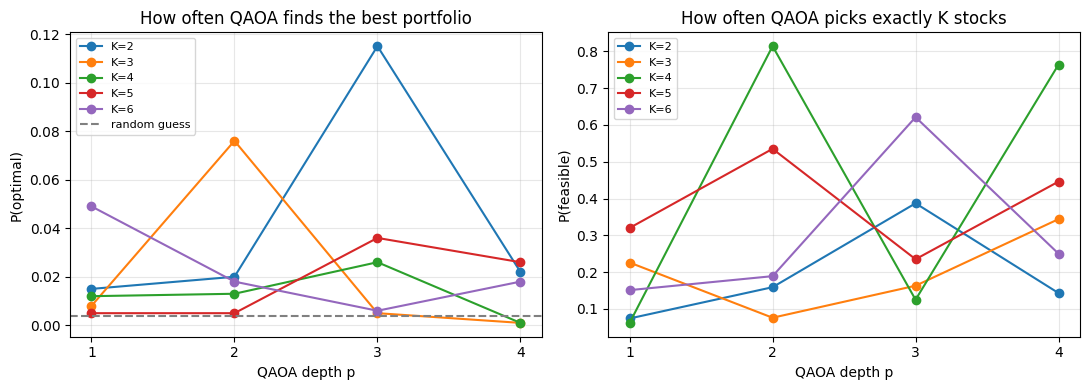

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for K_ in K_values:
  d = results[results.K == K_]
  ax[0].plot(d.p, d.P_optimal, "o-", label=f"K={K_}")
  ax[1].plot(d.p, d.P_feasible, "o-", label=f"K={K_}")
ax[0].axhline(1/256, color="gray", ls="--", label="random guess")
ax[0].set_title("How often QAOA finds the best portfolio"); ax[0].set_ylabel("P(optimal)")
ax[1].set_title("How often QAOA picks exactly K stocks"); ax[1].set_ylabel("P(feasible)")

for a in ax:
  a.set_xlabel("QAOA depth p"); a.set_xticks(p_values); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

/tmp/ipykernel_829/1175296507.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  test_prices = yf.download(tickers + ["SPY"], start=test_start, end=test_end)["Close"]
[*********************100%***********************]  9 of 9 completed


Test period: 2025-01-01 to 2026-11-13

                                   Total return %  Yearly volatility %  \
Brute-force best: NVDA, XOM, JPM             52.9                 21.5   
QAOA most-sampled: NVDA, JPM, PFE            37.9                 21.5   
All 8 stocks, equal weight                   54.3                 15.3   
S&P 500 (SPY)                                32.0                 17.2   

                                   Worst drop from peak %  
Brute-force best: NVDA, XOM, JPM                    -21.0  
QAOA most-sampled: NVDA, JPM, PFE                   -22.6  
All 8 stocks, equal weight                          -18.5  
S&P 500 (SPY)                                       -18.8  


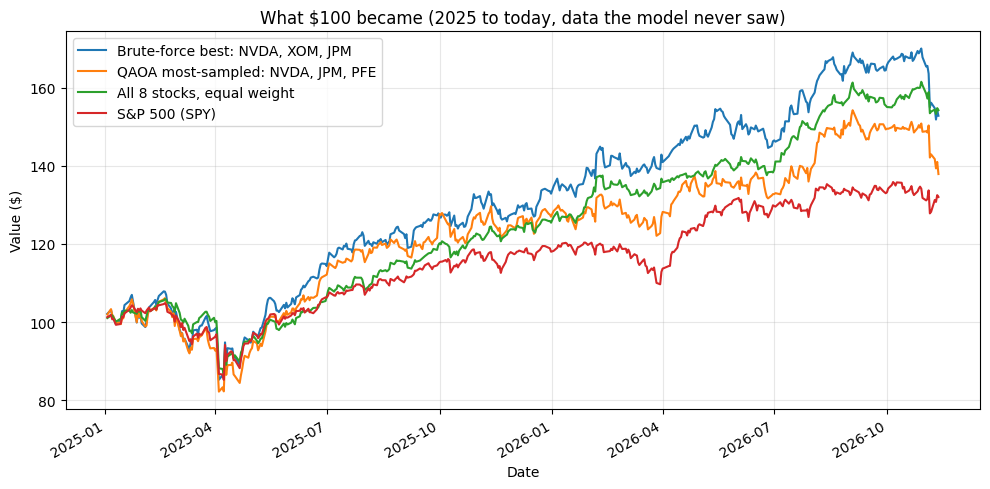

In [ ]:
# --- Backtest: how did our picks do on NEW data (2025 to today)? ---
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

test_start = "2025-01-01"
test_end   = pd.Timestamp.today().strftime("%Y-%m-%d")

# Download the same 8 stocks + SPY (tracks the S&P 500) for the test period
test_prices = yf.download(tickers + ["SPY"], start=test_start, end=test_end)["Close"]
test_returns = test_prices.pct_change().dropna()

# Portfolios to compare (equal money in each stock)
portfolios = {
    "Brute-force best: NVDA, XOM, JPM":  ["NVDA", "XOM", "JPM"],
    "QAOA most-sampled: NVDA, JPM, PFE": ["NVDA", "JPM", "PFE"],
    "All 8 stocks, equal weight":        tickers,
}

# Grow $1 in each portfolio day by day
growth = {}
for name, stocks in portfolios.items():
    daily = test_returns[stocks].mean(axis=1)      # average return of the stocks held
    growth[name] = (1 + daily).cumprod()
growth["S&P 500 (SPY)"] = (1 + test_returns["SPY"]).cumprod()
growth = pd.DataFrame(growth)

# Summary table
daily_all = growth.pct_change().dropna()
summary = pd.DataFrame({
    "Total return %":         (growth.iloc[-1] - 1) * 100,
    "Yearly volatility %":    daily_all.std() * np.sqrt(252) * 100,
    "Worst drop from peak %": (growth / growth.cummax() - 1).min() * 100,
}).round(1)
print(f"Test period: {test_start} to {test_end}\n")
print(summary)

# Chart: what $100 invested on Jan 1, 2025 became
(growth * 100).plot(figsize=(10, 5))
plt.title("What $100 became (2025 to today, data the model never saw)")
plt.ylabel("Value ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# --- Accuracy check: did 2022-2024 data predict 2025-now correctly? ---
from itertools import product

# Same mu and sigma calculation, but on the NEW data
mu_test    = test_returns[tickers].mean() * 252
sigma_test = test_returns[tickers].cov()  * 252

# 1) Predicted vs actual, stock by stock
compare = pd.DataFrame({
    "Predicted return % (2022-24)": mu * 100,
    "Actual return % (2025-now)":   mu_test * 100,
    "Predicted risk % (2022-24)":   np.sqrt(np.diag(sigma)) * 100,
    "Actual risk % (2025-now)":     np.sqrt(np.diag(sigma_test)) * 100,
}).round(1)
print("How well did 2022-2024 predict 2025-now?\n")
print(compare)

# 2) Brute force again, using what ACTUALLY happened
hindsight = sorted(
    (portfolio_cost(b, mu_test.values, sigma_test.values, q, K, A), b)
    for b in product([0, 1], repeat=n)
)

def names(bits):
    return [tickers[i] for i in range(n) if bits[i] == 1]

print("\nBest portfolio in hindsight:", names(hindsight[0][1]))

# 3) Where does our pick rank among all valid 3-stock portfolios?
our_pick = tuple(1 if t in ["NVDA", "XOM", "JPM"] else 0 for t in tickers)
feasible = [b for _, b in hindsight if sum(b) == K]
print(f"Our pick (NVDA, XOM, JPM) ranks #{feasible.index(our_pick) + 1} "
      f"out of {len(feasible)} possible 3-stock portfolios")

How well did 2022-2024 predict 2025-now?

        Predicted return % (2022-24)  Actual return % (2025-now)  \
Ticker                                                             
AAPL                            14.9                        25.0   
NVDA                            65.2                        20.3   
XOM                             24.9                        31.1   
CVX                             13.7                        28.0   
JPM                             19.1                        24.3   
BAC                              4.8                        12.4   
JNJ                             -1.5                        41.2   
PFE                            -17.9                        14.4   

        Predicted risk % (2022-24)  Actual risk % (2025-now)  
Ticker                                                        
AAPL                          27.1                      29.7  
NVDA                          55.3                      45.2  
XOM                      

===== Jan 2025 to Sept 2026: 2025-01-03 to 2026-09-30 =====


,Total return %,Yearly volatility %,Worst drop from peak %
"Brute-force best: NVDA, XOM, JPM",64.5,21.6,-21.0
"QAOA most-sampled: NVDA, JPM, PFE",49.4,21.6,-22.6
"All 8 stocks, equal weight",55.5,15.5,-18.5
S&P 500 (SPY),33.0,17.1,-18.8


Best portfolio in hindsight: ['NVDA', 'XOM', 'JNJ']
Our pick ranks #17 of 56


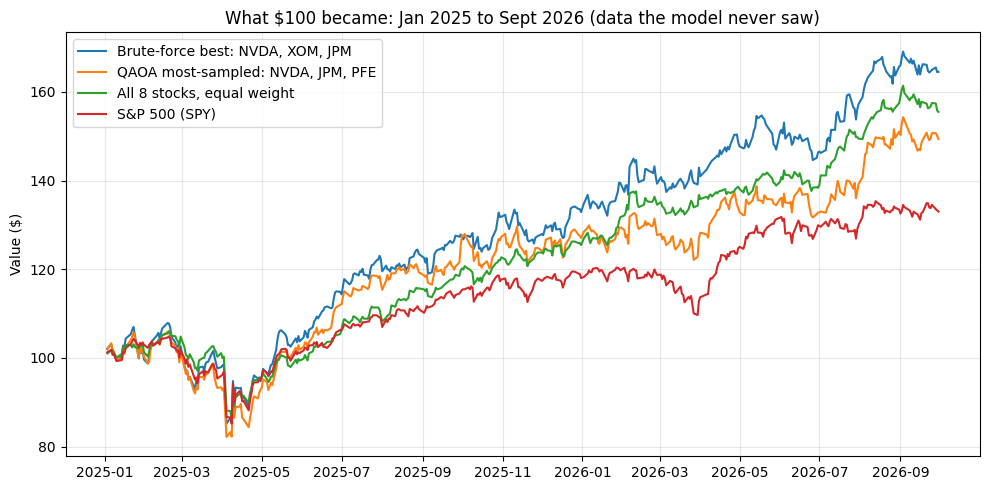

In [ ]:
# --- Backtest: Jan 2025 to Sept 2026 only ---
def backtest(prices, label):
    rets = prices.pct_change().dropna()

    # What $1 became in each portfolio
    growth = {}
    for name, stocks in portfolios.items():
        growth[name] = (1 + rets[stocks].mean(axis=1)).cumprod()
    growth["S&P 500 (SPY)"] = (1 + rets["SPY"]).cumprod()
    growth = pd.DataFrame(growth)

    daily = growth.pct_change().dropna()
    summary = pd.DataFrame({
        "Total return %":         (growth.iloc[-1] - 1) * 100,
        "Yearly volatility %":    daily.std() * np.sqrt(252) * 100,
        "Worst drop from peak %": (growth / growth.cummax() - 1).min() * 100,
    }).round(1)

    # Hindsight brute force for this period
    mu_t, sigma_t = rets[tickers].mean() * 252, rets[tickers].cov() * 252
    ranked = sorted((portfolio_cost(b, mu_t.values, sigma_t.values, q, K, A), b)
                    for b in product([0, 1], repeat=n))
    feasible = [b for _, b in ranked if sum(b) == K]
    our_pick = tuple(1 if t in ["NVDA", "XOM", "JPM"] else 0 for t in tickers)

    print(f"===== {label}: {rets.index[0].date()} to {rets.index[-1].date()} =====")
    display(summary)    # shows a clean table, good for a screenshot
    print("Best portfolio in hindsight:", [tickers[i] for i in range(n) if feasible[0][i]])
    print(f"Our pick ranks #{feasible.index(our_pick) + 1} of {len(feasible)}")
    return growth

def plot_growth(growth, title):
    plt.figure(figsize=(10, 5))
    for col in growth.columns:
        plt.plot(growth.index, growth[col] * 100, label=col)
    plt.title(title)
    plt.ylabel("Value ($)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Thing 1: the table
growth_sep = backtest(test_prices.loc[:"2026-09-30"], "Jan 2025 to Sept 2026")

# Thing 2: the chart
plot_growth(growth_sep, "What $100 became: Jan 2025 to Sept 2026 (data the model never saw)")